# World Bank EDA: Egypt and similar countries

Dataset #9 from the team's dataset list: World Bank, World Development Indicators (WDI).

**Goal:** find out what this data can answer for the project, what it can't, and what data is still needed from Egyptian companies.

- **Source:** https://databank.worldbank.org/data/download/WDI_CSV.zip
- **Countries:** Egypt, countries with similar economies (Morocco, Tunisia, Jordan, Turkey, Nigeria, Pakistan), and two Gulf countries to compare with (Saudi Arabia, UAE)
- **Years:** 2000 to 2025
- **Indicators:** inflation, official exchange rate, GDP growth, lending interest rate

In [1]:
from pathlib import Path
import zipfile

import pandas as pd
import matplotlib.pyplot as plt

## 1. Settings

In [2]:
countries = {
    "EGY": "Egypt",
    "MAR": "Morocco",
    "TUN": "Tunisia",
    "JOR": "Jordan",
    "TUR": "Turkey",
    "NGA": "Nigeria",
    "PAK": "Pakistan",
    "SAU": "Saudi Arabia",
    "ARE": "UAE",
}

indicators = {
    "FP.CPI.TOTL.ZG": "inflation",
    "PA.NUS.FCRF": "exchange_rate",
    "NY.GDP.MKTP.KD.ZG": "gdp_growth",
    "FR.INR.LEND": "lending_rate",
}

years = [str(year) for year in range(2000, 2026)]

data_dir = Path("Data")
if not data_dir.exists():
    data_dir = Path("../Data")
zip_path = data_dir / "raw" / "WDI_CSV.zip"
extract_path = data_dir / "raw" / "wdi_egypt_and_peers.csv"

## 2. Load the data

In [3]:
if extract_path.exists():
    wdi = pd.read_csv(extract_path)
else:
    with zipfile.ZipFile(zip_path) as z:
        full = pd.read_csv(z.open("WDICSV.csv"))
    print("Full WDI file:", full.shape)
    keep = full["Country Code"].isin(countries) & full["Indicator Code"].isin(indicators)
    wdi = full.loc[keep, ["Country Name", "Country Code", "Indicator Name", "Indicator Code"] + years]
    wdi.to_csv(extract_path, index=False)

print("Extract:", wdi.shape)
wdi.head()

Extract: (36, 30)


,Country Name,Country Code,Indicator Name,Indicator Code,2000,2001,2002,2003,2004,2005,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,"Egypt, Arab Rep.",EGY,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,6.370004,3.535252,2.390204,3.193455,4.092072,4.471744,...,4.346643,4.181221,5.331109,5.552093,3.550165,3.290646,6.587846,3.760281,2.399169,4.392011
1,"Egypt, Arab Rep.",EGY,"Inflation, consumer prices (annual %)",FP.CPI.TOTL.ZG,2.683805,2.269757,2.737239,4.507776,11.270619,4.869397,...,13.813606,29.506608,14.401466,9.152800,5.044933,5.214049,13.895661,33.884776,28.270590,14.073514
2,"Egypt, Arab Rep.",EGY,Lending interest rate (%),FR.INR.LEND,13.215833,13.291667,13.791667,13.533333,13.375000,13.141667,...,13.600000,18.175000,18.316667,16.116667,11.366667,9.425000,10.583333,17.758333,24.291667,NaN
3,"Egypt, Arab Rep.",EGY,"Official exchange rate (LCU per US$, period av...",PA.NUS.FCRF,3.472050,3.973000,4.499667,5.850875,6.196242,5.778833,...,10.025401,17.782534,17.767290,16.770582,15.759173,15.644527,19.160440,30.626414,45.299260,49.227756
4,Jordan,JOR,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,4.245712,5.269958,5.783808,4.161668,8.567214,8.146595,...,2.111668,2.507704,1.853834,1.856330,-1.152575,3.752013,2.746862,3.129001,2.556059,2.826608


In [4]:
wdi[["Indicator Code", "Indicator Name"]].drop_duplicates()

,Indicator Code,Indicator Name
0,NY.GDP.MKTP.KD.ZG,GDP growth (annual %)
1,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)"
2,FR.INR.LEND,Lending interest rate (%)
3,PA.NUS.FCRF,"Official exchange rate (LCU per US$, period av..."


The data is wide: one row per country and indicator, and one column per year. Here it is changed to one row per country and year, with one column per indicator. This is easier to check and plot.

In [5]:
long = wdi.melt(
    id_vars=["Country Code", "Indicator Code"],
    value_vars=years,
    var_name="year",
    value_name="value",
)
long["year"] = long["year"].astype(int)
long["country"] = long["Country Code"].map(countries)
long["indicator"] = long["Indicator Code"].map(indicators)

df = long.pivot(index=["country", "year"], columns="indicator", values="value").reset_index()
df.columns.name = None
df.head()

,country,year,exchange_rate,gdp_growth,inflation,lending_rate
0,Egypt,2000,3.472050,6.370004,2.683805,13.215833
1,Egypt,2001,3.973000,3.535252,2.269757,13.291667
2,Egypt,2002,4.499667,2.390204,2.737239,13.791667
3,Egypt,2003,5.850875,3.193455,4.507776,13.533333
4,Egypt,2004,6.196242,4.092072,11.270619,13.375000


## 3. Basic checks

In [6]:
print("Rows:", len(df))
print("Countries:", df["country"].nunique())
print("Years:", df["year"].min(), "to", df["year"].max())
print("Duplicate country-year rows:", df.duplicated(["country", "year"]).sum())
df.describe().round(2)

Rows: 234
Countries: 9
Years: 2000 to 2025
Duplicate country-year rows: 0


,year,exchange_rate,gdp_growth,inflation,lending_rate
count,234.00,234.00,233.00,226.00,95.00
mean,2012.50,52.43,4.02,8.10,12.79
std,7.52,159.08,3.29,10.52,4.12
min,2000.00,0.63,-8.98,-2.08,7.02
25%,2006.00,2.48,2.52,1.99,9.02
50%,2012.50,3.75,4.09,4.84,12.00
75%,2019.00,18.82,5.81,10.07,16.07
max,2025.00,1518.38,15.33,72.31,24.77


## 4. Missing values

In [7]:
# Number of missing years (out of 26) for each country and indicator
missing = df.set_index(["country", "year"]).isna().groupby("country").sum()
missing

,exchange_rate,gdp_growth,inflation,lending_rate
country,,,,
Egypt,0,0,0,1
Jordan,0,0,0,0
Morocco,0,0,0,26
Nigeria,0,0,0,0
Pakistan,0,0,0,8
Saudi Arabia,0,0,0,26
Tunisia,0,0,0,26
Turkey,0,0,0,26
UAE,0,1,8,26


In [8]:
egypt = df[df["country"] == "Egypt"].set_index("year")
egypt[egypt.isna().any(axis=1)]

,country,exchange_rate,gdp_growth,inflation,lending_rate
year,,,,,
2025,Egypt,49.227756,4.392011,14.073514,NaN


**Notes:**
- Egypt is almost complete. Only the 2025 lending rate is missing, probably because it is not published yet.
- The lending rate is missing for all 26 years in Morocco, Tunisia, Turkey, Saudi Arabia and the UAE, and for 8 years in Pakistan. So lending rates can only be compared for Egypt, Jordan, Nigeria and Pakistan.
- The UAE is also missing 8 years of inflation and 1 year of GDP growth.
- No duplicate rows.

## 5. Egypt over time

The red lines mark 2016 (the pound was floated in November 2016) and 2022 (the start of the most recent run of devaluations). The values are yearly averages, so a big drop late in a year shows up across that year and the next one.

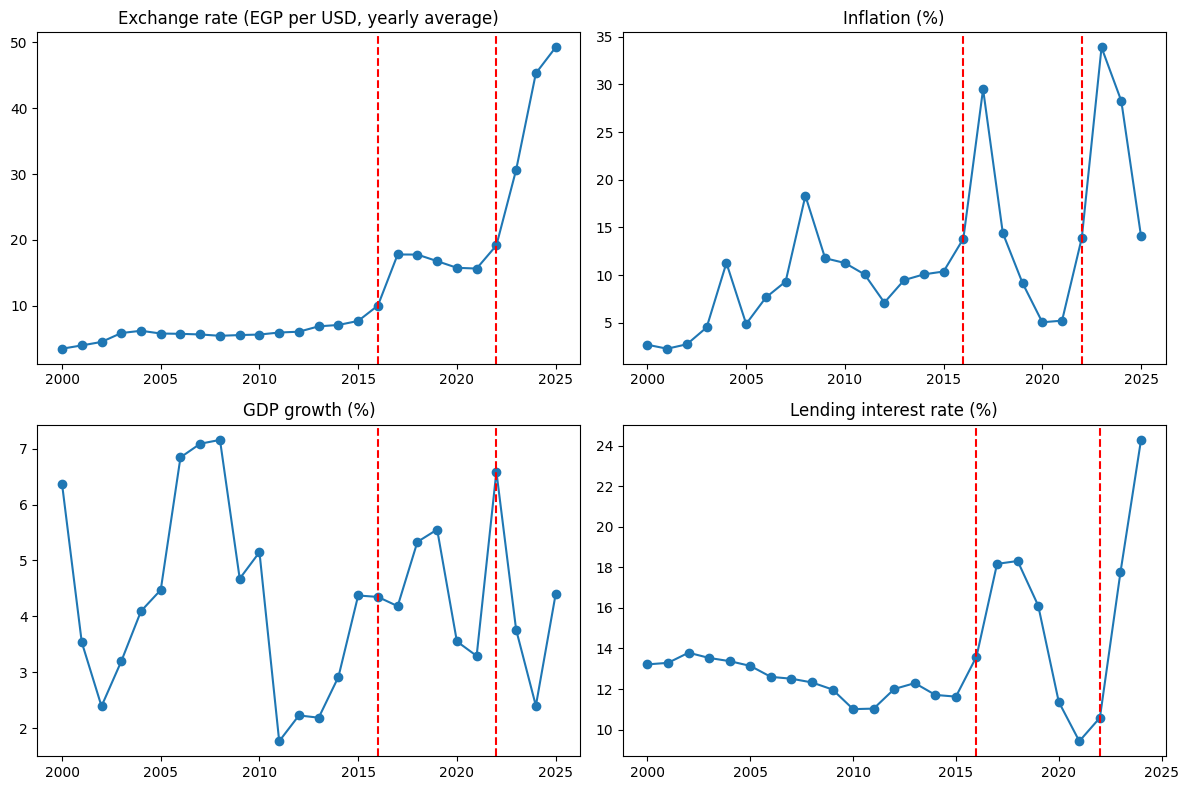

In [9]:
titles = {
    "exchange_rate": "Exchange rate (EGP per USD, yearly average)",
    "inflation": "Inflation (%)",
    "gdp_growth": "GDP growth (%)",
    "lending_rate": "Lending interest rate (%)",
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (column, title) in zip(axes.flat, titles.items()):
    ax.plot(egypt.index, egypt[column], marker="o")
    ax.axvline(2016, color="red", linestyle="--")
    ax.axvline(2022, color="red", linestyle="--")
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Notes:**
- The exchange rate stayed around 5 to 7 EGP per USD until 2015. Then it jumped twice: to about 18 in 2017, and to 45 to 49 in 2024 and 2025.
- Inflation peaks right after each jump: 29.5% in 2017 and 33.9% in 2023.
- The lending rate also went up after each jump, reaching 24.3% in 2024.
- GDP growth stayed positive every year (lowest 1.8% in 2011) and does not show the same big swings.

## 6. How big are the jumps?

This is useful for the simulator. If a founder asks "what if the pound drops?", the simulator needs a realistic size for the drop.

In [10]:
# Yearly % change in the exchange rate. A positive number means the pound lost value.
egypt["fx_change_pct"] = egypt["exchange_rate"].pct_change() * 100
egypt[["exchange_rate", "fx_change_pct", "inflation", "gdp_growth", "lending_rate"]].round(1)

,exchange_rate,fx_change_pct,inflation,gdp_growth,lending_rate
year,,,,,
2000,3.5,NaN,2.7,6.4,13.2
2001,4.0,14.4,2.3,3.5,13.3
2002,4.5,13.3,2.7,2.4,13.8
2003,5.9,30.0,4.5,3.2,13.5
2004,6.2,5.9,11.3,4.1,13.4
2005,5.8,-6.7,4.9,4.5,13.1
2006,5.7,-0.8,7.6,6.8,12.6
2007,5.6,-1.7,9.3,7.1,12.5
2008,5.4,-3.6,18.3,7.2,12.3


In [11]:
egypt["fx_change_pct"].sort_values(ascending=False).head(5).round(1)

year
2017    77.4
2023    59.8
2024    47.9
2016    30.3
2003    30.0
Name: fx_change_pct, dtype: float64

**Notes:**
- The biggest yearly drops of the pound: 77% in 2017, 60% in 2023, 48% in 2024, 30% in 2016 and 30% in 2003 (the 2003 float).
- Apart from these five years and 2022 (22.5%), the yearly change was under 15%, and in some years the pound gained a little.
- For the simulator, Egypt's own history gives three realistic shock sizes: about 10 to 20% (a normal bad year), about 30% (a float), and 50 to 80% (a crisis year). These are yearly averages, so the drop on a single day can be bigger.

## 7. Egypt compared with similar countries

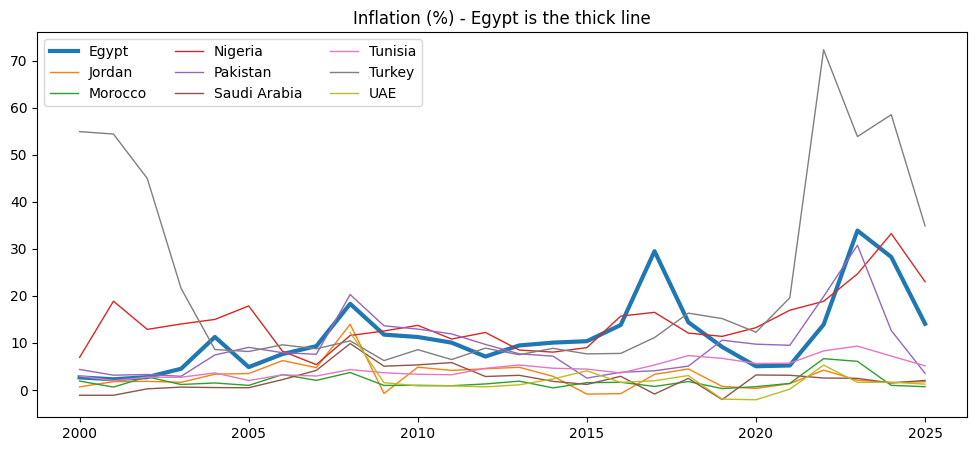

In [12]:
def plot_countries(column, title):
    fig, ax = plt.subplots(figsize=(12, 5))
    for name, group in df.groupby("country"):
        width = 3 if name == "Egypt" else 1
        ax.plot(group["year"], group[column], label=name, linewidth=width)
    ax.set_title(title)
    ax.legend(ncol=3)
    plt.show()


plot_countries("inflation", "Inflation (%) - Egypt is the thick line")

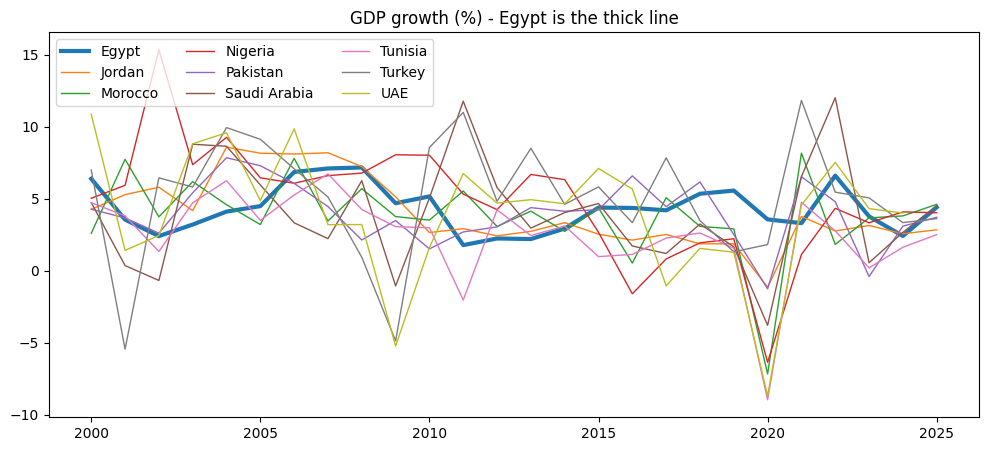

In [13]:
plot_countries("gdp_growth", "GDP growth (%) - Egypt is the thick line")

In [14]:
# Each country uses its own currency, so compare how much each rate changed from 2015 to 2025
rates = df.pivot(index="year", columns="country", values="exchange_rate")
change_since_2015 = (rates.loc[2025] / rates.loc[2015] - 1) * 100
change_since_2015.sort_values(ascending=False).round(0)

country
Turkey          1351.0
Nigeria          689.0
Egypt            540.0
Pakistan         174.0
Tunisia           53.0
Saudi Arabia       0.0
Jordan             0.0
UAE                0.0
Morocco           -4.0
dtype: float64

In [15]:
recent = df[df["year"] >= 2015]
recent.groupby("country")[["inflation", "gdp_growth", "lending_rate"]].mean().round(1).sort_values(
    "inflation", ascending=False
)

,inflation,gdp_growth,lending_rate
country,,,
Turkey,28.1,4.8,NaN
Nigeria,17.7,1.5,15.4
Egypt,16.1,4.3,15.1
Pakistan,10.2,3.7,9.6
Tunisia,6.2,1.0,NaN
Morocco,2.1,2.8,NaN
Jordan,1.7,2.2,8.2
Saudi Arabia,1.7,3.2,NaN
UAE,1.5,2.6,NaN


**Notes:**
- From 2015 to 2025 the dollar went from 7.7 to 49.2 pounds (+540%). Only Turkey (+1351%) and Nigeria (+689%) changed more.
- Saudi Arabia, the UAE and Jordan show 0% because their currencies are fixed to the dollar, and Morocco hardly changed. They are not good comparisons for currency risk.
- Since 2015, Egypt's average inflation (16.1%) is the third highest, after Turkey (28.1%) and Nigeria (17.7%).
- The countries most like Egypt for currency and inflation risk are Turkey, Nigeria and Pakistan. The Gulf countries are only useful as a stable contrast.

## 8. Do the indicators move together in Egypt?

A quick look only. With 25 yearly values this cannot show cause and effect. It uses the yearly change in the exchange rate, not the rate itself, because the rate mostly just goes up over time.

In [16]:
egypt[["fx_change_pct", "inflation", "gdp_growth", "lending_rate"]].corr().round(2)

,fx_change_pct,inflation,gdp_growth,lending_rate
fx_change_pct,1.00,0.75,-0.24,0.61
inflation,0.75,1.00,0.02,0.66
gdp_growth,-0.24,0.02,1.00,-0.11
lending_rate,0.61,0.66,-0.11,1.00


**Notes:**
- In Egypt, years with a bigger drop in the pound also had higher inflation (0.75) and higher lending rates (0.61).
- GDP growth is barely related to the others.
- This matches what happened in 2017 and 2023, but it is only 25 yearly values, so it is only background, not a model.

## 9. Save the clean table

In [17]:
clean_path = data_dir / "processed" / "wdi_egypt_and_peers_by_year.csv"
df.to_csv(clean_path, index=False)
print("Saved", clean_path, df.shape)

Saved ..\Data\processed\wdi_egypt_and_peers_by_year.csv (234, 6)


## 10. What kind of data is this?

- Country-level numbers from the World Bank: one value per country, per indicator, per year.
- Official and widely used. Almost nothing is missing for Egypt.
- Yearly averages only. No monthly data and nothing about single companies.

## 11. What questions can it answer?

The first 8 questions come from the project README. The last 2 are specific to this dataset.

| # | Question | Answer | Why |
|---|---|---|---|
| 1 | What is this startup's failure risk in the next 12 or 24 months? | No | Country-level data only. Nothing about single companies or whether they closed. |
| 2 | How likely is it to survive 1, 2, 3 or 5 years? | No | Same reason. No companies and no closing dates. |
| 3 | Does its growth rate make sense for its sector? | No | The extract only has GDP growth for the whole country, not by sector. |
| 4 | What happens to cash runway if expenses drop 20 to 25%? | No | Needs the company's own cash and monthly costs. |
| 5 | How would a currency devaluation or inflation affect the company? | Partly | Gives realistic shock sizes (section 6). But it doesn't show how much of each company's costs are in dollars. |
| 6 | How is the Egyptian market doing? What are funding conditions? | Partly | Gives the economic background: inflation, interest rates and growth. No sector or startup funding data. |
| 7 | How does my startup compare with its sector? | No | No sector data. |
| 8 | Why is the risk high? Which factors matter? | No | There is no model to explain. It can only add context, for example "inflation was 34% in 2023". |
| 9 | How did the exchange rate and inflation change after the 2016 float and in 2022 to 2024? | Yes | Sections 5 and 6. |
| 10 | Which countries are most like Egypt for currency and inflation risk? | Yes | Section 7: Turkey, Nigeria and Pakistan. |

## 12. How it can help the project

- Realistic currency and inflation shock sizes for the simulator (section 6).
- Dated facts about the Egyptian economy for RAG answers, for example "inflation was 33.9% in 2023".
- Choosing comparison countries for Egypt: Turkey, Nigeria and Pakistan.
- It can't predict anything about a single startup, because it only has country-level numbers.

The clean table is saved in `Data/processed/wdi_egypt_and_peers_by_year.csv`.

## 13. What data is still needed

The biggest gap is company data. To answer "how would a devaluation affect my company?", the project needs to know how much of each company's costs and revenue is in dollars.

**To ask Egyptian companies:**
- Cash they have now, and the minimum cash they want to keep.
- Monthly cash coming in and going out.
- Share of costs paid in dollars or linked to the dollar (imports, software, rent in USD). Needed for question 5.
- Share of revenue in dollars (exports, foreign clients).
- Loans: amount, interest rate, and whether the rate is fixed or changes. Needed to use the lending-rate data.
- Sector and business model.
- Funding raised so far, and when they expect the next funding.

**From other sources:**
- Monthly exchange rates and the policy interest rate from the Central Bank of Egypt. The World Bank only has yearly averages, and its lending rate is not the Central Bank's policy rate.
- Monthly inflation from CAPMAS.
- Egyptian data by sector.